In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator

In [2]:
n = 5

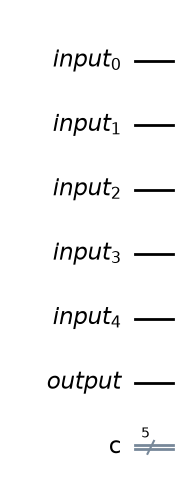

In [3]:
input_qubits = QuantumRegister(n, name='input')
output_qubit = QuantumRegister(1, name='output')

cr = ClassicalRegister(n, name='c')
qc = QuantumCircuit(input_qubits, output_qubit, cr)
qc.draw(output='mpl')

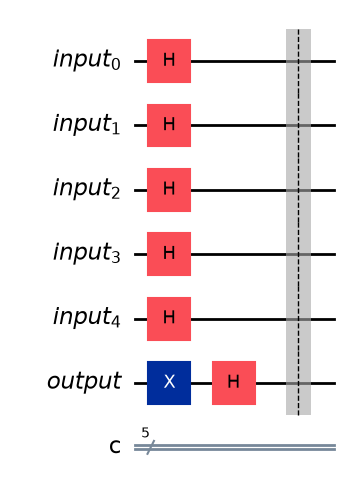

In [4]:
qc.h(input_qubits)
qc.x(output_qubit)
qc.h(output_qubit)
qc.barrier()
qc.draw(output='mpl')

In [5]:
def create_oracle(function_type, n):
    oracle = QuantumCircuit(n + 1, name = "Oracle")

    if function_type == "constant_0":
        pass

    elif function_type == "constant_1":
        oracle.x(n)
        oracle.barrier()

    elif function_type == "balanced_same_input":
        oracle.cx(0, n)

    elif function_type == "balanced_not":
        oracle.cx(0, n)
        oracle.x(n)

    return oracle

        

In [6]:
oracle = create_oracle("balanced_same_input", n)
qc.append(oracle, list(range(n + 1)))

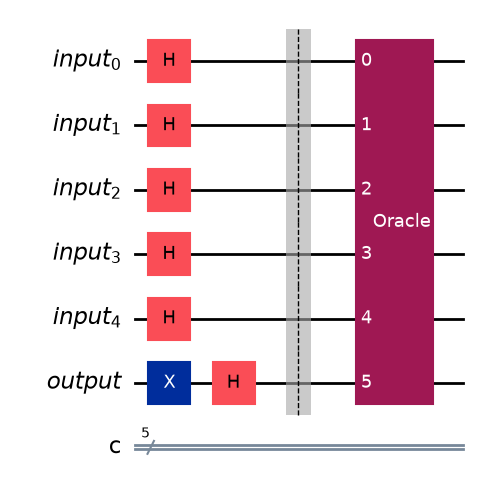

In [7]:
qc.draw(output='mpl')

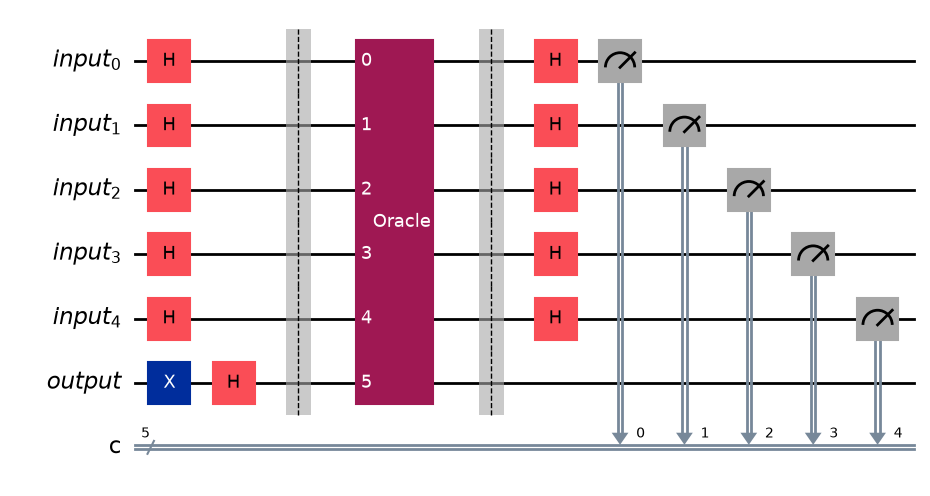

In [8]:
qc.barrier()
qc.h(input_qubits)
qc.measure(input_qubits, cr)
qc.draw("mpl")

In [9]:
aer_sim = AerSimulator()
transpiled_qc = transpile(qc, aer_sim)
job = aer_sim.run(transpiled_qc, shots=1)
result = job.result()
counts = result.get_counts()
print(counts)

{'00001': 1}
